In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
# cargar archivos
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')
eco = pd.read_csv('/datasets/oecd_city_economy.csv')

In [ ]:
print("=== TomTom Tráfico ===")
print(traffic.head())

=== TomTom Tráfico ===
  Country       City            UpdateTimeUTC  JamsDelay  TrafficIndexLive  \
0     ARE  abu-dhabi  2025-01-13 04:01:30.001      650.7              36.0   
1     ARE  abu-dhabi  2025-01-13 03:46:00.000      540.4              30.0   
2     ARE  abu-dhabi  2025-01-13 02:46:30.000       71.8               7.0   
3     ARE  abu-dhabi  2025-01-13 01:46:30.001        8.2               2.0   
4     ARE  abu-dhabi  2025-01-13 00:01:30.000        1.1               1.0   

   JamsLengthInKms  JamsCount  TrafficIndexWeekAgo     UpdateTimeUTCWeekAgo  \
0            109.1      162.0                 30.0  2025-01-06 04:01:30.000   
1            101.4      136.0                 27.0  2025-01-06 03:46:30.001   
2             18.9       23.0                  6.0  2025-01-06 02:46:30.000   
3              4.1        2.0                  2.0  2025-01-06 01:46:30.000   
4              0.2        1.0                  1.0  2025-01-06 00:01:30.000   

   TravelTimeLivePer10KmsMins  Tr

In [ ]:
print("\n=== Economía de Ciudades OCDE ===")
print(eco.head())


=== Economía de Ciudades OCDE ===
   Year            City    Country City GDP/capita Unemployment %  \
0  2023    buenos-aires  Argentina       15.782,00           6.2%   
1  2023       sao-paulo     Brazil       14.475,00           9.1%   
2  2023  rio-de-janeiro     Brazil       13.142,00           9.8%   
3  2023        brasilia     Brazil       15.999,00           8.3%   
4  2023        salvador     Brazil        8.761,00          13.1%   

  PM2.5 (μg/m³) Population (M)  
0          15,2          15,30  
1         29,50          22,50  
2         19,10          13,60  
3         13,50           4,70  
4         16,00           3,90  


In [ ]:
print("=== Estructura del DataFrame ===")
traffic.info()


=== Estructura del DataFrame ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  object 
 1   City                            1004464 non-null  object 
 2   UpdateTimeUTC                   1004464 non-null  object 
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  object 
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                     

In [ ]:
print("=== Estructura del DataFrame ===")
eco.info()


=== Estructura del DataFrame ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Year             30 non-null     int64 
 1   City             30 non-null     object
 2   Country          30 non-null     object
 3   City GDP/capita  30 non-null     object
 4   Unemployment %   30 non-null     object
 5   PM2.5 (μg/m³)    30 non-null     object
 6   Population (M)   30 non-null     object
dtypes: int64(1), object(6)
memory usage: 1.8+ KB


In [ ]:
# Estandarizar los nombres de las columnas de traffic
#tu código aquí
traffic = pd.read_csv('/datasets/tomtom_traffic.csv')

# Renombrar las columnas solicitadas
traffic = traffic.rename(columns={
    'Country': 'country',
    'UpdateTimeUTC': 'update_time_utc', 'City': 'city', 'JamsDelay': 'jams_delay', 'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms':'jams_length_kms', 'JamsCount': 'jams_count', 'MinsDelay': 'mins_delay',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins', 'TravelTimeHistoricPer10KmsMins': 'travel_time_hist_per_10kms_mins'
})

# Verificar que los cambios se aplicaron
print(traffic.columns.tolist())
# verificar cambios
#traffic.columns

['country', 'city', 'update_time_utc', 'jams_delay', 'traffic_index_live', 'jams_length_kms', 'jams_count', 'TrafficIndexWeekAgo', 'UpdateTimeUTCWeekAgo', 'travel_time_live_per_10kms_mins', 'travel_time_hist_per_10kms_mins', 'mins_delay']


In [ ]:
# Estandarizar los nombres de las columnas de eco
#tu código aquí
eco = pd.read_csv('/datasets/oecd_city_economy.csv')
eco = eco.rename(columns={
    'Country': 'country',
    'UpdateTimeUTC': 'update_time_utc', 'City GDP/capita':'city_gdp_capita','Unemployment %':'unemployment_pct',
    'Population (M)':'population_m','Year':'year','City':'city', 'PM2.5 (μg/m³)':'pm25'
})

# Verificar que los cambios se aplicaron
print(eco.columns.tolist())

# verificar cambios
#eco.columns

['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct', 'pm25', 'population_m']


In [ ]:
# Convertir las columnas de traffic a tipo fecha con pd.to_datetime()
import pandas as pd

traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')
traffic['update_time_utc'] = pd.to_datetime(traffic['update_time_utc'], errors='coerce')

# verificar el cambio
traffic.info()

eco['city_gdp_capita'] = (
    eco['city_gdp_capita']
    .str.replace('.', '', regex=False)  # elimina separadores de miles
    .str.replace(',', '.', regex=False) # cambia coma decimal por punto
    .astype(float)
)

eco['population_m'] = (
    eco['population_m']
    .str.replace(',', '.', regex=False)
    .astype(float)
)

eco['population'] = eco['population_m'] * 1_000_000

print(eco[['city_gdp_capita', 'unemployment_pct', 'population_m', 'population']].head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 13 columns):
 #   Column                           Non-Null Count    Dtype         
---  ------                           --------------    -----         
 0   country                          1004464 non-null  object        
 1   city                             1004464 non-null  object        
 2   update_time_utc                  1004464 non-null  datetime64[ns]
 3   jams_delay                       1004464 non-null  float64       
 4   traffic_index_live               1004464 non-null  float64       
 5   jams_length_kms                  1004464 non-null  float64       
 6   jams_count                       1004464 non-null  float64       
 7   TrafficIndexWeekAgo              1004464 non-null  float64       
 8   UpdateTimeUTCWeekAgo             1004464 non-null  object        
 9   travel_time_live_per_10kms_mins  1004464 non-null  float64       
 10  travel_time_hist_per_10kms_min

In [ ]:
# Limpia separadores y convierte columnas numéricas en eco
# eco['city_gdp_capita'] = ....astype(str).str.replace('.', '').str.replace(',', '.').astype(float)
eco['city_gdp_capita'] = eco['city_gdp_capita'].astype(str).str.replace(',', '').str.replace('.', '.').astype(float)
eco['unemployment_pct'] = eco['unemployment_pct'].astype(str).str.replace(',', '').str.replace('%', '').astype(float)
# eco['unemployment_pct'] = ...
# eco['population_m'] = ...
eco['population'] = eco['population_m'] * 1_000_000
# Calcula la población total en unidades absolutas (Multiplica * 1000000)
# eco['population'] = ...

# verificar el cambio
eco.info()
print("\n--- Primeras filas ---")
print(eco.head(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     object 
 2   country           30 non-null     object 
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     object 
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), object(3)
memory usage: 2.0+ KB

--- Primeras filas ---
   year            city    country  city_gdp_capita  unemployment_pct   pm25  \
0  2023    buenos-aires  Argentina          15782.0               6.2   15,2   
1  2023       sao-paulo     Brazil          14475.0               9.1  29,50   
2  2023  rio-de-janeiro     Brazil          13142.0               9.8  19,10   

   population_m  popu

In [ ]:
# Extraer el año de las fechas en update_time_utc
traffic['year'] = pd.to_datetime(traffic['update_time_utc']).dt.year
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()
# Verificar cambio
print(traffic_2024['year'].unique())  # Confirma que solo queda 2024
#traffic_2024.head(3)
traffic.head(3)

[2024]


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [ ]:
# Filtra los registros del año 2024
# traffic_2024 = traffic[...].copy()
traffic_2024 = traffic[traffic['year'] == 2024].copy()
# eco_2024 = ...
eco_2024 = eco[eco['year'] == 2024].copy()
# Revisar dataframes nuevos
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_kms,jams_count,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0


In [ ]:
# Calcular los  promedios de trafico por ciudad, país y año
traffic_city_year_2024 = (
    traffic_2024
    .groupby(['city', 'country', 'year'], as_index=False)  # Agrupar y mantener como columnas
    .agg({
        'jams_delay': 'mean',
        'traffic_index_live': 'mean',
        'jams_length_kms': 'mean',
        'jams_count': 'mean',
        'mins_delay': 'mean',
        'travel_time_live_per_10kms_mins': 'mean',
        'travel_time_hist_per_10kms_mins': 'mean'
    })
)

# Mostrar resultado
traffic_city_year_2024.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [ ]:
traffic_city_year_2024.sort_values(["jams_delay"], ascending=False)

,city,country,year,jams_delay,traffic_index_live,jams_length_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_hist_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


La ciudad con el mayor tiempo promedio de tráfico es ... Ciudad de Mexico

In [ ]:
# Seleccionar columnas clave de tráfico y economía
left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins','travel_time_hist_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Usar .copy() para crear los dos nuevos datasets reducidos
# traffic_2024_small = traffic_city_year_2024[ ... ].copy()
# eco_2024_small = ...
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()
# Unir datasets
merged = pd.merge(
    traffic_2024_small,   # Tabla principal (tráfico)
    eco_2024_small,      # Tabla económica
    on=['city', 'year'],  # Claves de unión
    how='inner'           # Coincidencias en ambos
)

# Mostrar las primeras 5 filas
print(merged.head(5))

             city country  year   jams_delay  traffic_index_live  \
0  belo-horizonte     BRA  2024   263.047879           19.428946   
1          bogota     COL  2024  1141.552364           37.614273   
2        brasilia     BRA  2024   101.576326           11.258220   
3    buenos-aires     ARG  2024   571.089593           17.756012   
4        curitiba     BRA  2024   183.469274           14.954545   

   jams_length_kms  jams_count  mins_delay  travel_time_live_per_10kms_mins  \
0        44.038129   68.805422    0.487228                        18.304538   
1       140.893564  230.566550    1.699628                        24.992185   
2        18.337133   27.280140    0.193442                        13.338658   
3       100.287844  137.359860    0.416566                        17.907916   
4        30.050044   46.898164    0.139965                        17.258700   

   travel_time_hist_per_10kms_mins  city_gdp_capita  unemployment_pct   pm25  \
0                        17.817311  

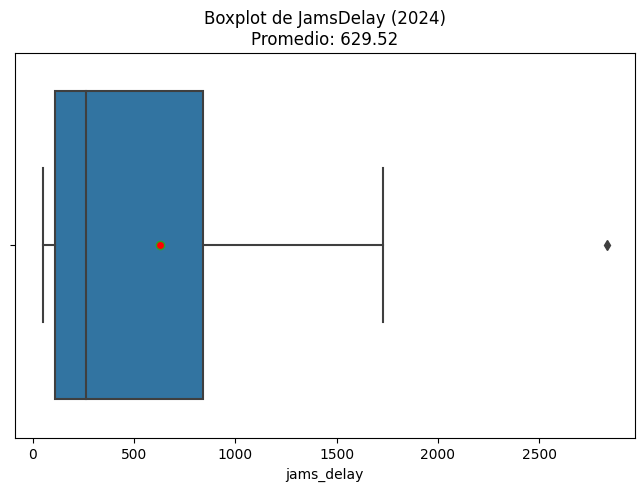

In [ ]:
# Crear boxplot para observar el comportamiento de los minutos de congestion JamsDelay
# crea tu gráfico
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
sns.boxplot(data=merged, x='jams_delay', showmeans=True, meanprops={"marker":"o", "markerfacecolor":"red"})

# obtener promedio para mostrarlo en título
mean_value = merged['jams_delay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}')
plt.show()


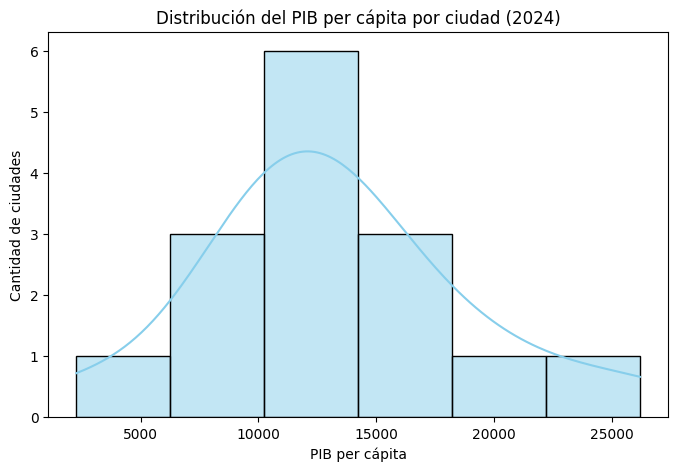

In [ ]:
# Crear histograma para ver la distribución de la economía (city_gdp_capita)
plt.figure(figsize=(8, 5))
sns.histplot(data=merged, x='city_gdp_capita', kde=True, color='skyblue')

plt.title('Distribución del PIB per cápita por ciudad (2024)')
plt.xlabel('PIB per cápita')
plt.ylabel('Cantidad de ciudades')
plt.show()


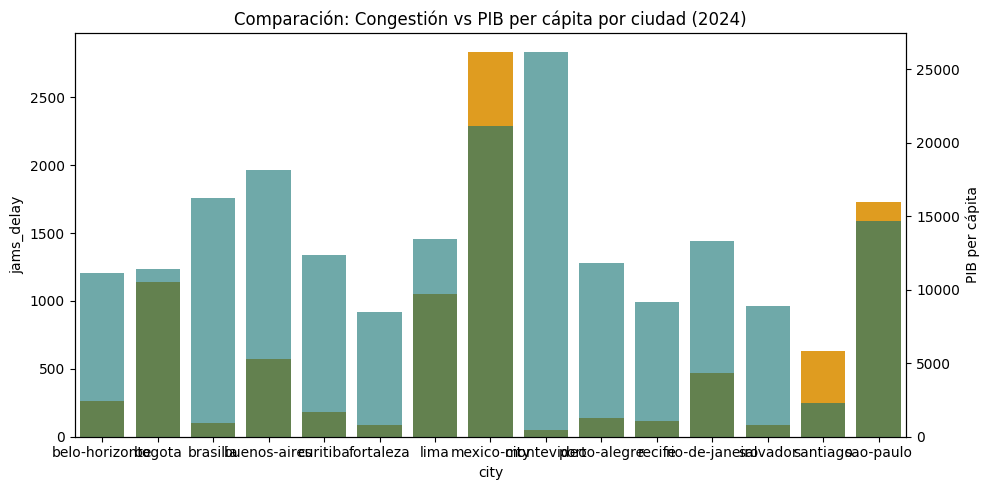

In [ ]:
# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
#merged.plot( ... , y=['jams_delay', 'city_gdp_capita'])
plt.figure(figsize=(10, 5))
# Usamos ciudad como eje X para mostrar ambos indicadores
sns.barplot(data=merged, x='city', y='jams_delay', color='orange', label='Demora promedio (min)')
ax2 = plt.twinx()
sns.barplot(data=merged, x='city', y='city_gdp_capita', color='teal', label='PIB per cápita', ax=ax2, alpha=0.6)

plt.title('Comparación: Congestión vs PIB per cápita por ciudad (2024)')
plt.xlabel('Ciudad')
plt.ylabel('Minutos de demora')
ax2.set_ylabel('PIB per cápita')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.xticks(rotation=90)
plt.show()

Comentarios: No se observa que las ciudades con mayor PIB per cápita presenten más congestión: sucede lo contrario. Las localidades con menores niveles de congestión vehicular y demoras en el tráfico registran los valores más altos de PIB por habitante, mientras que las ciudades con peor movilidad muestran los indicadores de productividad más bajos. Esto sugiere una relación inversa clara: una mayor congestión se asocia a menor desempeño económico, sin que se cumpla el supuesto de que ciudades más ricas tengan necesariamente más tráfico.

In [ ]:
# Exporta el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

-Se busca identificar la relación entre la congestión vehicular y tiempos de viaje (indicadores de movilidad) y
el PIB per cápita (productividad económica) de las ciudades.
-Las variables clave son: demora en congestión, índice de tráfico, duración de recorridos, PIB per cápita, tasa de desempleo y tamaño de población.
Se analizaron registros correspondientes al año 2024, integrando información de ciudades de América Latina, entre ellas
Bogotá, Lima y Buenos Aires.
-Se realizó la limpieza y estandarización: se corrigieron formatos numéricos, se normalizaron nombres de columnas
al formato snake_case, se agregaron los indicadores de tráfico promedio por ciudad y año, y se integraron con los datos económicos
localidades con información completa en ambos conjuntos.
Finalmente se validaron distribuciones, valores atípicos y tendencias mediante gráficos de caja, histogramas y
comparaciones directas.Se observa una tendencia general: mayores niveles de congestión se asocian a valores menores de PIB per cápita,
lo que sugiere que los retrasos en la movilidad limitan la actividad económica. Bogotá y Lima presentan las demoras
más altas y los indicadores de productividad más bajos del grupo, mientras que ciudades con mejor flujo vehicular
registran un PIB per cápita superior. Se detectaron valores extremos en demoras que requieren verificación adicional
para descartar errores de medición.
-Prioridad de inversión: Bogotá y Lima son las localidades donde la congestión tiene la correlación más fuerte con baja productividad, por lo que deben ser el foco principal para proyectos de mejora vial, transporte público y gestión del tráfico.
Validación: Revisar los registros con valores de demora inusualmente altos para confirmar su fiabilidad.
Análisis complementario: Estudiar el impacto específico de la congestión en sectores económicos clave, y monitorear la evolución de estos indicadores anualmente para medir la efectividad de las intervenciones.
